# 3. Labels: cheap ones to train on, careful ones to judge by

A segmentation model needs a "right answer" for every pixel it trains on. Hand-drawing water
masks for hundreds of scenes is weeks of work, so this project uses **weak labels**: answers
that already exist, for free, but are known to be imperfect.

A model can learn useful things from noisy labels. But it must **never be judged** by them,
or you'll end up measuring how well it copies the noise. So there are two separate kinds of
label here:

| | weak labels | hand labels |
|---|---|---|
| used for | training | evaluation only |
| coverage | every pixel of every training scene | 660 points on 18 scenes |
| quality | systematically wrong in places | careful, but a small sample |

In [1]:
from hlw.nb import BLUE, GREY, ORANGE, setup

setup()
import numpy as np
import pandas as pd

from hlw import aoi, labels
from hlw import config as C
from hlw.dataset import s2_path, s2_scl_path
from hlw.io import read_raster
import matplotlib.pyplot as plt

## Five free sources of "water"

* **JRC ≥ 50 %**: pixels that were water in at least half of 36 years of Landsat images.
  Static: it doesn't know what the lake looked like on *our* date.
* **ESA WorldCover 2021**, class "permanent water": a single 2021 snapshot.
* **Impact Observatory LULC**, class "water": one map per year, 2017-2023.
* **Sentinel-2 SCL**, class "water": produced automatically for *every* scene, alongside the
  imagery itself. Date-specific, but made by a fairly simple rule-based classifier.
* **SCL ∩ JRC** (our choice): SCL water, but only where JRC has ever seen water. SCL water
  outside JRC's history (often a cloud shadow or dark roof) is marked "ignore", not "land".

Let's look at all five on one date when the lake was far from its long-term average: Lake
Travis near its October 2023 drought low.

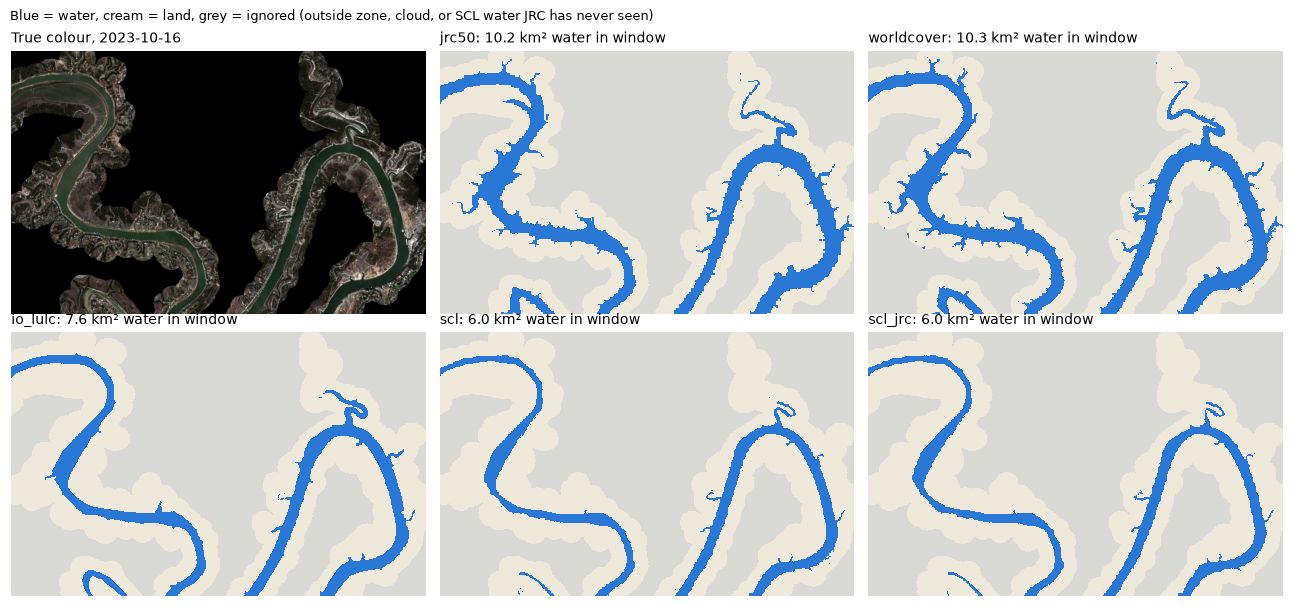

In [2]:
LAKE, DATE = "travis", "2023-10-16"
refl = read_raster(s2_path(LAKE, DATE))[0]
scl = read_raster(s2_scl_path(LAKE, DATE))[0][0]
zone, _, _ = aoi.load_zone(LAKE)
static = labels.static_layers(LAKE)
sl = (slice(1000, 1700), slice(1500, 2600))

cmap = plt.matplotlib.colors.ListedColormap(["#efe9dc", BLUE, "#d9d9d6"])
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
from hlw.blogfigs import rgb

axes[0, 0].imshow(rgb(refl, zone & (refl[2] > 0), sl))
axes[0, 0].set_title(f"True colour, {DATE}")
for ax, kind in zip(axes.flat[1:], labels.LABEL_KINDS):
    lab = labels.weak_label(kind, scl, zone, static, int(DATE[:4]))[sl]
    show = np.where(lab == 255, 2, lab)
    ax.imshow(show, cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
    w = (lab == 1).sum() * 100 / 1e6
    ax.set_title(f"{kind}: {w:.1f} km² water in window")
for ax in axes.flat:
    ax.set_axis_off()
fig.suptitle("Blue = water, cream = land, grey = ignored (outside zone, cloud, or "
             "SCL water JRC has never seen)", x=0.01, ha="left", fontsize=9.5)
plt.tight_layout()

**JRC** and **WorldCover** draw the lake as it usually looks, so in a drought they label large
areas of exposed lakebed as "water": 10 km² in this window against 6 km² that was really
there. **IO LULC** is an annual map (here 2023, a drought year), so it lands in between. A model trained on them
learns to paint the average lake whatever the image shows. That's useless for monitoring,
where the point is to see change.

The **SCL** maps follow the actual shoreline on this date, because they were made from this
very image.

You can measure this. We compared each weak label with the hand-labelled points (described
below) and scored it exactly like a model:

In [3]:
noise = pd.read_csv(C.RESULTS_DIR / "weak_label_noise.csv")
noise[["label", "iou", "iou_lo", "iou_hi", "precision", "recall", "n"]].round(3)

,label,iou,iou_lo,iou_hi,precision,recall,n
0,jrc50,0.781,0.749,0.814,0.857,0.898,640
1,worldcover,0.813,0.778,0.845,0.858,0.940,640
2,io_lulc,0.832,0.797,0.870,0.931,0.887,640
3,scl,0.935,0.914,0.955,0.970,0.963,640
4,scl_jrc,0.935,0.912,0.956,0.971,0.962,633


The static labels score IoU 0.78-0.83. JRC and WorldCover have high recall and lower
precision: they say "water" too often, which is the drought problem above. IO LULC errs the
other way on some scenes (an annual map is wrong in both directions as the lake moves within
the year). SCL scores 0.94.

Then we trained the same model on each label (notebook 5), and the label quality comes straight
through: on the same held-out points, the model trained on JRC labels scores **0.78**, and the
one trained on SCL ∩ JRC scores **0.96**. A model can't learn its way out of a label that is wrong in a consistent
way. Choosing the label was the single biggest decision in the project, bigger than
pretraining or architecture.

> **Where weak labels mislead.** A model can score well *against its own kind of label* while
> being wrong about the world. Had we validated the JRC-trained model against held-out JRC
> labels, it would have looked excellent.

## Hand labels: points, not masks

For evaluation we want independent, careful labels, but drawing complete masks is slow and
shoreline pixels are hard to call. The standard alternative in remote sensing is to label a
**random sample of points** and estimate accuracy statistically (Olofsson et al., 2014,
*Good practices for estimating area and assessing accuracy of land change*).

The catch: purely random points would land almost entirely in open water or on dry land,
where every method is right. So we **stratify** by the JRC water history and oversample the
interesting band:

* **A**: JRC occurrence ≥ 90 % (stable water), 20 % of points
* **B**: occurrence 1-89 % (the fluctuation zone), 55 % of points
* **C**: occurrence 0 (never water in 36 years), 25 % of points

The strata come from JRC only, which none of the compared methods sees at prediction time, so
the sampling doesn't favour any of them.

In [4]:
pts = pd.read_csv(C.LABELS_DIR / "hand_points.csv")  # points, strata and the AI labels
human = pd.read_csv(C.LABELS_DIR / "hand_points_human_final.csv")[["pid", "label"]]
pts = pts.merge(human.rename(columns={"label": "label_human"}), on="pid")
print(len(pts), "points on", pts.scene.nunique(), "scenes")
name = {1: "water", 0: "not water", -1: "unsure"}
t = pd.crosstab(pts.stratum, pts.label_human.map(name))
t["stratum pixels (mean per scene)"] = pts.groupby("stratum").stratum_pixels.mean().round(-3)
t

660 points on 18 scenes


label_human,not water,unsure,water,stratum pixels (mean per scene)
stratum,,,,
A,1,0,131,357000.0
B,151,18,197,306000.0
C,151,2,9,614000.0


These are the **primary labels**: one person (the project author) labelled all 660 points
blind in a browser tool (`make label-tool`) that never shows a model's answer or anyone
else's label. Two things stand out:

1. **Strata A and C are almost pure.** 131 of 132 confident A points are water; 151 of 160 C
   points are not water. Labelling them confirms the obvious. That's fine: they are cheap, and
   they keep the estimate honest over the whole zone.
2. **Stratum B holds nearly all the information**, and most of the doubt: 18 of its 366
   points were marked *unsure* and dropped from scoring.

### Two answer keys

The same points were also labelled by Claude Opus 5.5, an AI model, looking at the same image chips.
That is deliberate: AI-assisted labelling is fast and increasingly common, and the project
asks whether it gives the same verdict as a person. The AI labels are in the repo
(`labels/hand_points.csv`), and every result is also scored against them
(`results/ai_labels/`). Comparing the two is a lesson in itself:

In [5]:
both = pts[pts.label.isin([0, 1]) & pts.label_human.isin([0, 1])]
print(pd.crosstab(pts.label.map(name).rename("AI"), pts.label_human.map(name).rename("human")))
print(f"\nagreement where both committed: {(both.label == both.label_human).mean():.3f} "
      f"(n = {len(both)})")

human      not water  unsure  water
AI                                 
not water        257      13      9
unsure            38       5     56
water              8       2    272

agreement where both committed: 0.969 (n = 546)


They agree on 97 % of the points both labelled. The big difference is commitment: the AI
marked **99** points unsure, mostly shoreline, against the person's 20. Unsure points are
dropped from scoring, so the AI labels quietly removed the hardest pixels, exactly where
methods disagree. That pushed every method's score up and **towards a tie**, and it hid a
real difference between methods (notebooks 4 and 6).

The person's labels were also checked against themselves. The 26 points where the two
labellers disagreed were shuffled with 26 points they agreed on and labelled again, blind.
None of the control points flipped between water and not water. Of the 26 conflicts, 17 kept
the first answer, 7 became unsure and 2 switched to the AI's answer. The final labels use the
second look.

## Why stratified points need weights

Because B was oversampled, a raw "fraction of points correct" would over-represent the
shoreline and give the wrong answer for the lake as a whole. Each point stands in for
`stratum_pixels / points_in_stratum` pixels of its scene. Weighting by that gives unbiased
estimates of the true number of water/land pixels each method gets right and wrong, and IoU
follows from those.

Here is the difference it makes, using one method's predictions:

In [6]:
from hlw.metrics import estimate

scored = pd.read_csv(C.RESULTS_DIR / "points_scored.csv")
scored = scored[scored.label.isin([0, 1])].copy()
scored["pred"] = scored["pred_mndwi_tuned"].astype(int)
y, p = scored.label.astype(bool), scored.pred.astype(bool)
naive_iou = (y & p).sum() / (y | p).sum()
print(f"MNDWI, unweighted point IoU:          {naive_iou:.3f}")
print(f"MNDWI, stratified (Olofsson) IoU:     {estimate(scored, 'pred')['iou']:.3f}")
print(f"shoreline stratum B only, unweighted: "
      f"{((y & p)[scored.stratum == 'B']).sum() / ((y | p)[scored.stratum == 'B']).sum():.3f}")

MNDWI, unweighted point IoU:          0.927
MNDWI, stratified (Olofsson) IoU:     0.940
shoreline stratum B only, unweighted: 0.896


The weighted estimate is higher than the raw one because the oversampled shoreline, where the
errors live, really is a small part of the lake. The shoreline-only number shows where the
contest actually is. Both views are useful: the weighted IoU answers "how good is the map of
the whole lake?", the stratum-B number answers "how good is it where it matters?".

Confidence intervals come from a **stratified bootstrap**: resample points within each
(scene, stratum) cell, recompute, repeat 500 times. With 500 or so points the intervals are
roughly ±0.02 IoU, which is wider than most of the differences between good methods. That's
why notebook 6 uses *paired* comparisons.

## Takeaways

* Weak labels are fine for **training** if their errors are not systematic in the way you care
  about. Static water maps fail that test for a reservoir in drought; per-scene SCL passes.
* Never evaluate on weak labels. Keep a separate, independent, carefully made test set.
* Stratify the test set towards the hard pixels, and weight the estimate back to the population.
* "Unsure" is not free. Every dropped point is a hard one, so a cautious labeller makes the
  test easier. Prefer a labeller who commits where they can, and check them with a blind
  second look.

Next: [4 · baselines and honest splits](04_baselines_and_splits.ipynb)